In [1]:
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 10.0 MB 7.4 MB/s eta 0:00:01
     |████████████████████████████████| 233 kB 83.2 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path

PROJECT = Path.cwd().parent
PROCESSED = PROJECT / "data" / "processed"
FIGS = PROJECT / "figures"
TABLES = PROJECT / "tables"

df = pd.read_csv(PROCESSED / "daily_dataset.csv", index_col="date", parse_dates=True)
END = df["MKT_RF"].last_valid_index()          # Fama-French end date
d = df.loc[:END].copy()
print("Sample:", d.index.min().date(), "to", END.date(), "|", len(d), "trading days")

SECTORS = {
    "ITA": "Defence & aerospace", "XLE": "Energy",
    "JETS": "Airlines", "XLY": "Consumer discretionary", "XLK": "Technology",
    "XLF": "Financials", "XLV": "Health care", "XLP": "Consumer staples",
    "XLI": "Industrials", "XLB": "Materials", "XLU": "Utilities",
    "XLRE": "Real estate", "XLC": "Communication",
}
WINNERS, LOSERS = ["ITA", "XLE"], ["JETS", "XLY", "XLK"]   # H3 predictions
FACTORS = ["MKT_RF", "SMB", "HML", "RMW", "CMA"]

Sample: 2015-01-02 to 2026-08-31 | 2932 trading days


In [3]:
pre = d.loc[:"2021-12-31"]
for raw, z in [("DGPRT", "Z_T"), ("DGPRA", "Z_A"), ("DGPR", "Z_G")]:
    d[z] = d[raw] / pre[raw].std()
    d[z + "_L1"] = d[z].shift(1)            # yesterday's GPR change

for s in SECTORS:
    d[f"EX_{s}"] = d[f"RET_{s}"] - d["RF"]

r = d["Z_T"].corr(d["Z_A"])
print(f"corr(threat change, act change) = {r:.2f}   VIF = {1/(1-r**2):.2f}")
print(d[["Z_T", "Z_A"]].describe().round(2))

corr(threat change, act change) = 0.24   VIF = 1.06
           Z_T      Z_A
count  2931.00  2931.00
mean      0.00     0.00
std       0.93     0.87
min      -5.42    -6.16
25%      -0.61    -0.49
50%       0.01    -0.00
75%       0.58     0.52
max       4.73     5.91


In [4]:
def ols_hac(y, X, data, lags=5):
    sub = data[[y] + X].dropna()
    return sm.OLS(sub[y], sm.add_constant(sub[X])).fit(cov_type="HAC", cov_kwds={"maxlags": lags})

def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

In [5]:
for X in [["Z_T", "Z_A"], ["Z_T", "Z_A", "Z_T_L1", "Z_A_L1"]]:
    m = ols_hac("RET_GSPC", X, d)
    print(f"S&P 500 on {X}   (n = {int(m.nobs)})")
    print(m.summary2().tables[1][["Coef.", "Std.Err.", "P>|z|"]].round(3), "\n")

S&P 500 on ['Z_T', 'Z_A']   (n = 2931)
       Coef.  Std.Err.  P>|z|
const  0.045     0.019  0.017
Z_T    0.043     0.024  0.070
Z_A    0.007     0.024  0.766 

S&P 500 on ['Z_T', 'Z_A', 'Z_T_L1', 'Z_A_L1']   (n = 2930)
        Coef.  Std.Err.  P>|z|
const   0.046     0.019  0.016
Z_T     0.050     0.025  0.043
Z_A    -0.008     0.026  0.750
Z_T_L1  0.016     0.023  0.494
Z_A_L1 -0.033     0.024  0.166 



In [6]:
rows = []
for s, label in SECTORS.items():
    for mname, y, X in [("total",           f"RET_{s}", ["Z_T", "Z_A"]),
                        ("factor-adjusted", f"EX_{s}",  FACTORS + ["Z_T", "Z_A"])]:
        m = ols_hac(y, X, d)
        p_eq = float(np.squeeze(m.t_test("Z_T - Z_A = 0").pvalue))
        ci = m.conf_int()
        for v in ["Z_T", "Z_A"]:
            rows.append({"ticker": s, "sector": label, "model": mname, "var": v,
                         "coef": m.params[v], "se": m.bse[v], "p": m.pvalues[v],
                         "lo": ci.loc[v, 0], "hi": ci.loc[v, 1],
                         "n": int(m.nobs), "p_threat_eq_act": p_eq})
sec = pd.DataFrame(rows)
sec.to_csv(TABLES / "sector_regressions.csv", index=False)

sec["cell"] = sec["coef"].map("{:.3f}".format) + sec["p"].apply(stars)
tab = sec.pivot_table(index="sector", columns=["model", "var"], values="cell", aggfunc="first")
tab = tab.reindex(index=[SECTORS[s] for s in SECTORS])
tab["n"] = sec.groupby("sector")["n"].first()
tab["p (threat = act), adj."] = (sec[sec.model == "factor-adjusted"]
                                 .groupby("sector")["p_threat_eq_act"].first().round(3))
print("Coefficient = return (pp) per 1-SD daily GPR change.  * p<.10 ** p<.05 *** p<.01")
display(tab)

Coefficient = return (pp) per 1-SD daily GPR change.  * p<.10 ** p<.05 *** p<.01


model                  factor-adjusted            total               n  \
var                                Z_A      Z_T     Z_A       Z_T         
sector                                                                    
Defence & aerospace             -0.012    0.016   0.015     0.035  2931   
Energy                          -0.010    0.021   0.048     0.027  2931   
Airlines                        -0.012    0.001   0.031     0.002  2850   
Consumer discretionary          -0.003  -0.019*  -0.001     0.023  2931   
Technology                      0.020*   -0.000   0.010   0.069**  2931   
Financials                      -0.010   -0.002   0.031     0.015  2931   
Health care                   -0.028**   0.025*  -0.024  0.057***  2931   
Consumer staples                -0.010    0.005   0.002     0.026  2931   
Industrials                     -0.003    0.006   0.023     0.029  2931   
Materials                        0.005    0.009   0.031     0.032  2931   
Utilities                        0.027    0.014   0.040     0.036  2931   
Real estate                      0.016   -0.022   0.034    -0.002  2738   
Communication                    0.001    0.011   0.008     0.055  2060   

model                  p (threat = act), adj.  
var                                            
sector                                         
Defence & aerospace                     0.317  
Energy                                  0.391  
Airlines                                0.786  
Consumer discretionary                  0.401  
Technology                              0.202  
Financials                              0.602  
Health care                             0.015  
Consumer staples                        0.465  
Industrials                             0.588  
Materials                               0.818  
Utilities                               0.690  
Real estate                             0.241  
Communication                           0.692

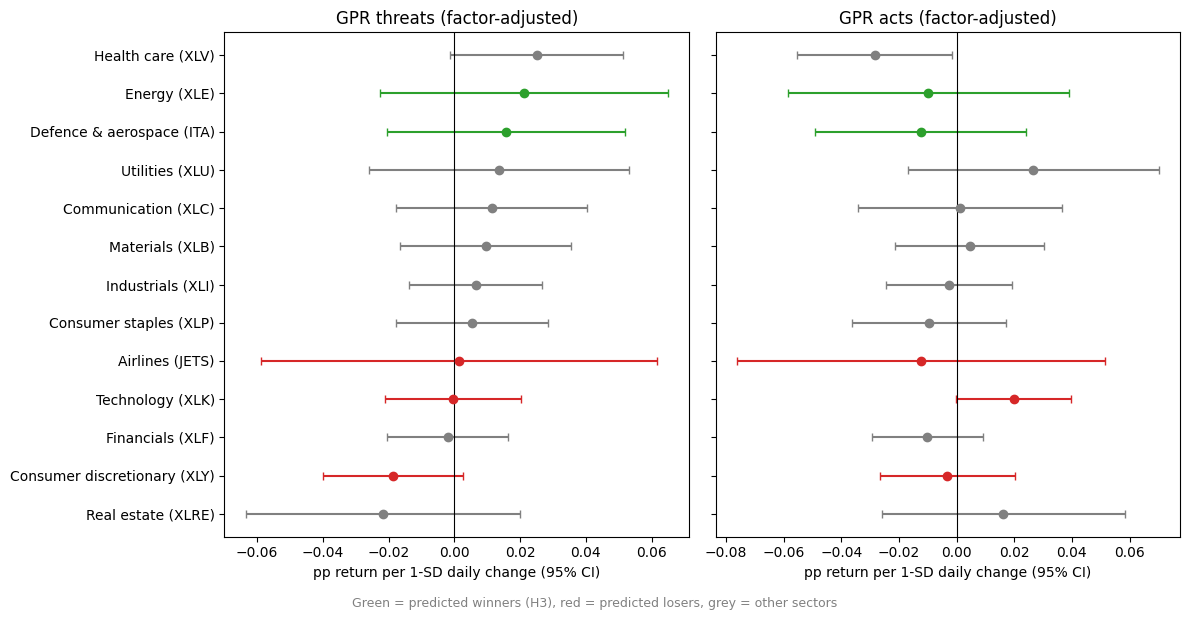

In [7]:
adj = sec[sec["model"] == "factor-adjusted"]
order = (adj[adj["var"] == "Z_T"].sort_values("coef")["ticker"]).tolist()

def colour(t):
    return "tab:green" if t in WINNERS else "tab:red" if t in LOSERS else "grey"

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
for ax, (v, title) in zip(axes, [("Z_T", "GPR threats"), ("Z_A", "GPR acts")]):
    a = adj[adj["var"] == v].set_index("ticker").loc[order]
    y = np.arange(len(a))
    for i, t in enumerate(a.index):
        ax.errorbar(a.loc[t, "coef"], i,
                    xerr=[[a.loc[t, "coef"] - a.loc[t, "lo"]], [a.loc[t, "hi"] - a.loc[t, "coef"]]],
                    fmt="o", color=colour(t), capsize=3)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{title} (factor-adjusted)")
    ax.set_xlabel("pp return per 1-SD daily change (95% CI)")
axes[0].set_yticks(np.arange(len(order)))
axes[0].set_yticklabels([f"{SECTORS[t]} ({t})" for t in order])
fig.text(0.5, -0.02, "Green = predicted winners (H3), red = predicted losers, grey = other sectors",
         ha="center", fontsize=9, color="grey")
plt.tight_layout()
plt.savefig(FIGS / "04_sector_coefficients.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
d["C_DEF_vs_LOS"] = d["RET_ITA"] - d[[f"RET_{t}" for t in LOSERS]].mean(axis=1, skipna=False)
d["C_ENE_vs_LOS"] = d["RET_XLE"] - d[[f"RET_{t}" for t in LOSERS]].mean(axis=1, skipna=False)
d["C_DEF_vs_ENE"] = d["RET_ITA"] - d["RET_XLE"]

crow = []
for c, label in [("C_DEF_vs_LOS", "Defence minus losers"),
                 ("C_ENE_vs_LOS", "Energy minus losers"),
                 ("C_DEF_vs_ENE", "Defence minus energy")]:
    m = ols_hac(c, FACTORS + ["Z_T", "Z_A"], d)
    crow.append({"contrast": label,
                 "threat coef": f"{m.params['Z_T']:.3f}{stars(m.pvalues['Z_T'])}",
                 "act coef":    f"{m.params['Z_A']:.3f}{stars(m.pvalues['Z_A'])}",
                 "joint p (both = 0)": round(float(np.squeeze(m.f_test("Z_T = 0, Z_A = 0").pvalue)), 4),
                 "p (threat = act)":   round(float(np.squeeze(m.t_test("Z_T - Z_A = 0").pvalue)), 4),
                 "n": int(m.nobs)})
contrasts = pd.DataFrame(crow).set_index("contrast")
display(contrasts)
contrasts.to_csv(TABLES / "h3_contrasts.csv")

,threat coef,act coef,joint p (both = 0),p (threat = act),n
contrast,,,,,
Defence minus losers,0.021,-0.015,0.4881,0.2399,2850
Energy minus losers,0.024,-0.012,0.6353,0.3727,2850
Defence minus energy,-0.005,-0.003,0.9732,0.9500,2931


In [9]:
lrow = []
for s, label in SECTORS.items():
    m = ols_hac(f"EX_{s}", FACTORS + ["Z_T", "Z_A", "Z_T_L1", "Z_A_L1"], d)
    lrow.append({"sector": label,
                 **{k: f"{m.params[k]:.3f}{stars(m.pvalues[k])}" for k in ["Z_T", "Z_T_L1", "Z_A", "Z_A_L1"]}})
lags = pd.DataFrame(lrow).set_index("sector")
display(lags)
lags.to_csv(TABLES / "sector_lags.csv")

,Z_T,Z_T_L1,Z_A,Z_A_L1
sector,,,,
Defence & aerospace,0.023,0.014,-0.021,-0.018
Energy,0.020,0.002,0.008,0.038
Airlines,0.029,0.059*,-0.027,-0.037
Consumer discretionary,-0.017,0.003,-0.012,-0.018
Technology,-0.006,-0.012,0.020*,0.002
Financials,-0.001,0.001,-0.015,-0.009
Health care,0.037**,0.026*,-0.033**,-0.012
Consumer staples,-0.006,-0.026*,-0.007,0.008
Industrials,0.009,0.005,-0.007,-0.009


In [10]:
EVENT_DAYS = ["2022-02-24", "2023-10-09", "2024-04-15", "2024-10-01",
              "2025-06-13", "2025-06-23", "2026-03-02"]
CONTRASTS = {"C_DEF_vs_LOS": "Defence minus losers",
             "C_ENE_vs_LOS": "Energy minus losers",
             "C_DEF_vs_ENE": "Defence minus energy"}

# flag the 5 trading days either side of each event (11-day windows)
mask = np.zeros(len(d), dtype=bool)
for day in EVENT_DAYS:
    p = d.index.get_loc(pd.Timestamp(day))
    mask[max(p - 5, 0): p + 6] = True
d["EVENT_WIN"] = mask
print(mask.sum(), "trading days fall inside event windows")

def run_set(data, label, lags=5):
    """Market (total), 13 sectors (factor-adjusted) and 3 contrasts on one sample."""
    rows = []
    specs = [("RET_GSPC", "S&P 500 (total)", [])]
    specs += [(f"EX_{s}", lab, FACTORS) for s, lab in SECTORS.items()]
    specs += [(c, lab, FACTORS) for c, lab in CONTRASTS.items()]
    for y, item, X0 in specs:
        m = ols_hac(y, X0 + ["Z_T", "Z_A"], data, lags)
        joint = float(np.squeeze(m.f_test("Z_T = 0, Z_A = 0").pvalue))
        for v in ["Z_T", "Z_A"]:
            rows.append({"spec": label, "item": item, "var": v, "coef": m.params[v],
                         "p": m.pvalues[v], "joint_p": joint, "n": int(m.nobs)})
    return rows

71 trading days fall inside event windows


In [11]:
all_rows = []
all_rows += run_set(d,                       "full daily")
all_rows += run_set(d[~d["EVENT_WIN"]],      "excl. event windows")
all_rows += run_set(d.loc[:"2022-02-23"],    "pre Feb 2022")
all_rows += run_set(d.loc["2022-02-24":],    "post Feb 2022")
print("Done:", len(all_rows), "coefficients")

Done: 136 coefficients


In [12]:
ret_cols = [c for c in d.columns if c.startswith(("RET_", "EX_", "C_"))] + FACTORS + ["RF"]
wk = d[ret_cols].resample("W-FRI").sum(min_count=1)        # weekly returns = sum of daily log returns

lvl = d[["GPRD_THREAT", "GPRD_ACT"]].resample("W-FRI").mean()   # average GPR level each week
for raw, z in [("GPRD_THREAT", "Z_T"), ("GPRD_ACT", "Z_A")]:
    chg = np.log1p(lvl[raw]).diff()
    wk[z] = chg / chg.loc[:"2021-12-31"].std()             # scale on pre-2022 weeks only

print(len(wk), "weeks")
all_rows += run_set(wk, "weekly", lags=4)

610 weeks


In [13]:
rob = pd.DataFrame(all_rows)
rob.to_csv(TABLES / "sector_robustness.csv", index=False)
rob["cell"] = rob["coef"].map("{:.3f}".format) + rob["p"].apply(stars)

SPECS = ["full daily", "excl. event windows", "pre Feb 2022", "post Feb 2022", "weekly"]
ITEMS = ["S&P 500 (total)"] + [SECTORS[s] for s in SECTORS] + list(CONTRASTS.values())

for v, title in [("Z_T", "THREATS"), ("Z_A", "ACTS")]:
    t = (rob[rob["var"] == v].pivot(index="item", columns="spec", values="cell")
         .reindex(index=ITEMS, columns=SPECS))
    print(f"\n{title}: coefficient per 1-SD change  (* p<.10 ** p<.05 *** p<.01)")
    display(t)

print("\nH3 contrasts: joint p-value (threat and act both = 0)")
jp = (rob[rob["item"].isin(CONTRASTS.values()) & (rob["var"] == "Z_T")]
      .pivot(index="item", columns="spec", values="joint_p").reindex(columns=SPECS).round(3))
display(jp)


THREATS: coefficient per 1-SD change  (* p<.10 ** p<.05 *** p<.01)


spec,full daily,excl. event windows,pre Feb 2022,post Feb 2022,weekly
item,,,,,
S&P 500 (total),0.043*,0.045*,0.074**,-0.033,-0.061
Defence & aerospace,0.016,0.021,0.031,-0.030,0.127
Energy,0.021,0.022,0.033,-0.058,-0.043
Airlines,0.001,0.003,0.016,-0.004,0.167
Consumer discretionary,-0.019*,-0.018*,-0.011,-0.014,-0.008
Technology,-0.000,-0.002,-0.001,0.019,-0.015
Financials,-0.002,-0.002,-0.011,0.008,0.027
Health care,0.025*,0.025*,0.015,0.002,0.102
Consumer staples,0.005,0.007,-0.010,0.026,-0.084



ACTS: coefficient per 1-SD change  (* p<.10 ** p<.05 *** p<.01)


spec,full daily,excl. event windows,pre Feb 2022,post Feb 2022,weekly
item,,,,,
S&P 500 (total),0.007,0.009,0.011,-0.012,0.049
Defence & aerospace,-0.012,-0.018,-0.028,0.049,0.052
Energy,-0.010,-0.015,-0.039,0.103*,0.187
Airlines,-0.012,-0.009,-0.008,-0.027,-0.238*
Consumer discretionary,-0.003,-0.003,0.001,-0.021,-0.068
Technology,0.020*,0.022**,0.023**,0.007,-0.033
Financials,-0.010,-0.010,0.004,-0.071***,-0.004
Health care,-0.028**,-0.028**,-0.027*,-0.023,0.041
Consumer staples,-0.010,-0.011,0.000,-0.042,0.043



H3 contrasts: joint p-value (threat and act both = 0)


spec,full daily,excl. event windows,pre Feb 2022,post Feb 2022,weekly
item,,,,,
Defence minus energy,0.973,0.993,0.946,0.755,0.381
Defence minus losers,0.488,0.266,0.101,0.420,0.102
Energy minus losers,0.635,0.555,0.183,0.205,0.126


In [14]:
d["POST"] = (d.index >= "2022-02-24").astype(int)
d["Z_T_POST"] = d["Z_T"] * d["POST"]
d["Z_A_POST"] = d["Z_A"] * d["POST"]

prow = []
for y, item, X0 in [("RET_GSPC", "S&P 500 (total)", [])] + [(c, l, FACTORS) for c, l in CONTRASTS.items()]:
    m = ols_hac(y, X0 + ["POST", "Z_T", "Z_A", "Z_T_POST", "Z_A_POST"], d)
    prow.append({"item": item,
                 "threat: pre":    f"{m.params['Z_T']:.3f}{stars(m.pvalues['Z_T'])}",
                 "threat: change": f"{m.params['Z_T_POST']:.3f}{stars(m.pvalues['Z_T_POST'])}",
                 "act: pre":       f"{m.params['Z_A']:.3f}{stars(m.pvalues['Z_A'])}",
                 "act: change":    f"{m.params['Z_A_POST']:.3f}{stars(m.pvalues['Z_A_POST'])}"})
display(pd.DataFrame(prow).set_index("item"))

,threat: pre,threat: change,act: pre,act: change
item,,,,
S&P 500 (total),0.074**,-0.107**,0.011,-0.023
Defence minus losers,0.036,-0.055,-0.033,0.095*
Energy minus losers,0.051*,-0.104,-0.046*,0.179**
Defence minus energy,-0.019,0.052,0.013,-0.083


In [15]:
d["OIL_POST"] = d["RET_WTI"] * d["POST"]
sample = d.dropna(subset=["RET_WTI"])          # same days for every model (oil trading days)
GPR_POST = ["POST", "Z_T", "Z_A", "Z_T_POST", "Z_A_POST"]

def post_effect(m, var):
    """Total post-2022 effect = pre coefficient + change."""
    tt = m.t_test(f"{var} + {var}_POST = 0")
    return float(np.squeeze(tt.effect)), float(np.squeeze(tt.pvalue))

# ---- Step 1: do GPR acts move oil, and did that change after Feb 2022? ----
m = ols_hac("RET_WTI", GPR_POST, sample)
print("STEP 1: oil return (%) on GPR changes")
for v, lab in [("Z_T", "threats"), ("Z_A", "acts")]:
    eff, p = post_effect(m, v)
    print(f"  {lab:8s} pre = {m.params[v]:6.3f}{stars(m.pvalues[v]):3s}  "
          f"change = {m.params[v+'_POST']:6.3f}{stars(m.pvalues[v+'_POST']):3s}  "
          f"post-2022 total = {eff:6.3f}{stars(p)}")

# ---- Step 2: does controlling for oil absorb the post-2022 act effect? ----
rows = []
for y, item in [("EX_XLE", "Energy"), ("EX_ITA", "Defence & aerospace"),
                ("C_ENE_vs_LOS", "Energy minus losers"), ("C_DEF_vs_LOS", "Defence minus losers"),
                ("RET_GSPC", "S&P 500 (total)")]:
    X0 = [] if y == "RET_GSPC" else FACTORS
    for label, extra in [("no oil", []), ("with oil", ["RET_WTI", "OIL_POST"])]:
        m = ols_hac(y, X0 + GPR_POST + extra, sample)
        eff_a, p_a = post_effect(m, "Z_A")
        eff_t, p_t = post_effect(m, "Z_T")
        row = {"item": item, "model": label,
               "act change":      f"{m.params['Z_A_POST']:.3f}{stars(m.pvalues['Z_A_POST'])}",
               "act post-2022":   f"{eff_a:.3f}{stars(p_a)}",
               "threat post-2022": f"{eff_t:.3f}{stars(p_t)}",
               "n": int(m.nobs)}
        if extra:
            beta, pb = post_effect(m, "RET_WTI".replace("RET_WTI", "RET_WTI")) if False else (None, None)
            row["oil beta pre / post"] = (f"{m.params['RET_WTI']:.3f} / "
                                          f"{m.params['RET_WTI'] + m.params['OIL_POST']:.3f}")
        rows.append(row)

oil_tab = pd.DataFrame(rows).set_index(["item", "model"])
print("\nSTEP 2: post-2022 GPR effects with and without the oil control")
display(oil_tab)
oil_tab.to_csv(TABLES / "oil_channel.csv")

STEP 1: oil return (%) on GPR changes
  threats  pre =  0.061     change = -0.106     post-2022 total = -0.045
  acts     pre = -0.017     change =  0.061     post-2022 total =  0.044

STEP 2: post-2022 GPR effects with and without the oil control


act change act post-2022 threat post-2022     n  \
item                 model                                                      
Energy               no oil      0.149**        0.104*           -0.037  2888   
                     with oil    0.136**       0.099**           -0.027  2888   
Defence & aerospace  no oil        0.058         0.031           -0.004  2888   
                     with oil      0.059         0.032           -0.005  2888   
Energy minus losers  no oil      0.179**        0.127*           -0.040  2820   
                     with oil    0.164**       0.120**           -0.027  2820   
Defence minus losers no oil        0.088         0.054           -0.007  2820   
                     with oil      0.086         0.053           -0.005  2820   
S&P 500 (total)      no oil       -0.020        -0.014           -0.028  2888   
                     with oil     -0.021        -0.014           -0.028  2888   

                              oil beta pre / post  
item                 model                         
Energy               no oil                   NaN  
                     with oil       0.154 / 0.305  
Defence & aerospace  no oil                   NaN  
                     with oil     -0.007 / -0.024  
Energy minus losers  no oil                   NaN  
                     with oil       0.172 / 0.370  
Defence minus losers no oil                   NaN  
                     with oil       0.013 / 0.039  
S&P 500 (total)      no oil                   NaN  
                     with oil       0.076 / 0.007